In [1]:
import pandas as pd
df = pd.read_csv(r"electricity_bill_data.csv")
df.head()

,household_id,family_members,home_area_sqft,ac_hours_per_day,appliance_count,avg_temperature_c,monthly_bill_inr
0,1,1,800,6.9,10,33.6,2289
1,2,6,1310,7.1,21,32.7,4107
2,3,5,1290,4.2,18,29.7,3587
3,4,4,1610,4.2,21,31.9,3975
4,5,4,1110,5.6,10,31.9,3297


In [2]:
df.shape

(200, 7)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   household_id       200 non-null    int64  
 1   family_members     200 non-null    int64  
 2   home_area_sqft     200 non-null    int64  
 3   ac_hours_per_day   200 non-null    float64
 4   appliance_count    200 non-null    int64  
 5   avg_temperature_c  200 non-null    float64
 6   monthly_bill_inr   200 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 11.1 KB


In [4]:
df.isnull().sum()

household_id         0
family_members       0
home_area_sqft       0
ac_hours_per_day     0
appliance_count      0
avg_temperature_c    0
monthly_bill_inr     0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

## Simple Linear Regression
- One Input - ac_hours_per_day
- Output - Monthly Bill INR
- y = mx + c

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
# Feature Selection - Feature and Target Data Split

X_simple = df[["ac_hours_per_day"]]
y = df["monthly_bill_inr"]

In [8]:
simple_model = LinearRegression()
simple_model.fit(X_simple, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[99.88]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['ac_hours_per_day']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3190
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [9]:
simple_pred = simple_model.predict(X_simple)
simple_pred

array([3879.60815563, 3899.58497545, 3609.92108806, 3609.92108806,
       3749.7588268 , 3569.96744842, 3839.65451599, 3619.90949797,
       3540.00221868, 3819.67769617, 3879.60815563, 4009.45748447,
       3789.71246644, 3679.83995743, 3819.67769617, 3380.18766012,
       3949.52702501, 4239.1909124 , 3969.50384483, 3490.06016913,
       4069.38794393, 3240.34992138, 3899.58497545, 4119.32999348,
       3440.11811958, 4019.44589438, 3480.07175922, 4099.35317366,
       3290.29197093, 4329.0866016 , 3749.7588268 , 4009.45748447,
       3879.60815563, 4099.35317366, 3989.48066465, 4289.13296196,
       4089.36476375, 3829.66610608, 3879.60815563, 3470.08334931,
       4169.27204303, 3420.14129976, 3669.85154752, 3769.73564662,
       3829.66610608, 3520.02539886, 4129.31840339, 3949.52702501,
       3979.49225474, 3440.11811958, 4019.44589438, 3190.40787183,
       3300.28038084, 3460.0949394 , 3889.59656554, 3659.86313761,
       3989.48066465, 3969.50384483, 3450.10652949, 4259.16773

In [10]:
plot_df = df[["ac_hours_per_day", "monthly_bill_inr"]].copy()
plot_df["Predicted_Bill"] = simple_pred
plot_df = plot_df.sort_values("ac_hours_per_day")

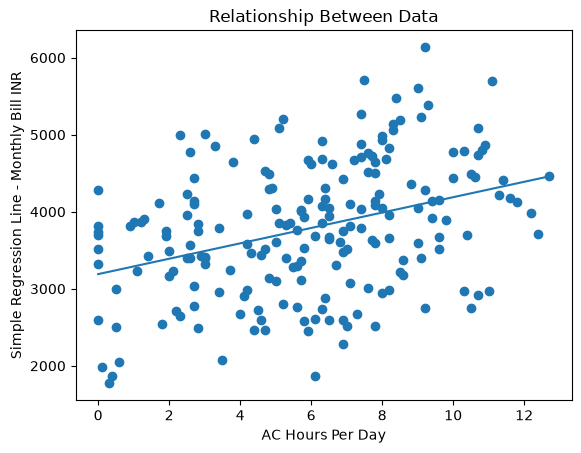

In [11]:
plt.scatter(df["ac_hours_per_day"], y)
plt.plot(plot_df["ac_hours_per_day"], plot_df["Predicted_Bill"])
plt.title("Relationship Between Data")
plt.xlabel("AC Hours Per Day")
plt.ylabel("Simple Regression Line - Monthly Bill INR")
plt.show()


In [12]:
results = pd.DataFrame({
    "Actual Bills" : y.values,
    "Predicted Bills" : simple_pred.round(0).astype(int)
})

results.head(10)

,Actual Bills,Predicted Bills
0,2289,3880
1,4107,3900
2,3587,3610
3,3975,3610
4,3297,3750
5,4646,3570
6,2600,3840
7,3468,3620
8,2081,3540
9,2736,3820


## Multiple Linear Regression
- inputs - Family Members, Home Area, Appliance Count, Avg Temperature
- output - monthly_bill_inr
- predicted bill = intercept + (coef * family_mem) + (coef * home_area)
- y = b0 + b1X1 + b2X2 + bkXk ... +

In [13]:
df.head()

,household_id,family_members,home_area_sqft,ac_hours_per_day,appliance_count,avg_temperature_c,monthly_bill_inr
0,1,1,800,6.9,10,33.6,2289
1,2,6,1310,7.1,21,32.7,4107
2,3,5,1290,4.2,18,29.7,3587
3,4,4,1610,4.2,21,31.9,3975
4,5,4,1110,5.6,10,31.9,3297


In [14]:
features = ["family_members", "home_area_sqft", "appliance_count","avg_temperature_c"]
X = df[features]
y = df["monthly_bill_inr"]

In [15]:
X.shape

(200, 4)

In [16]:
y.shape

(200,)

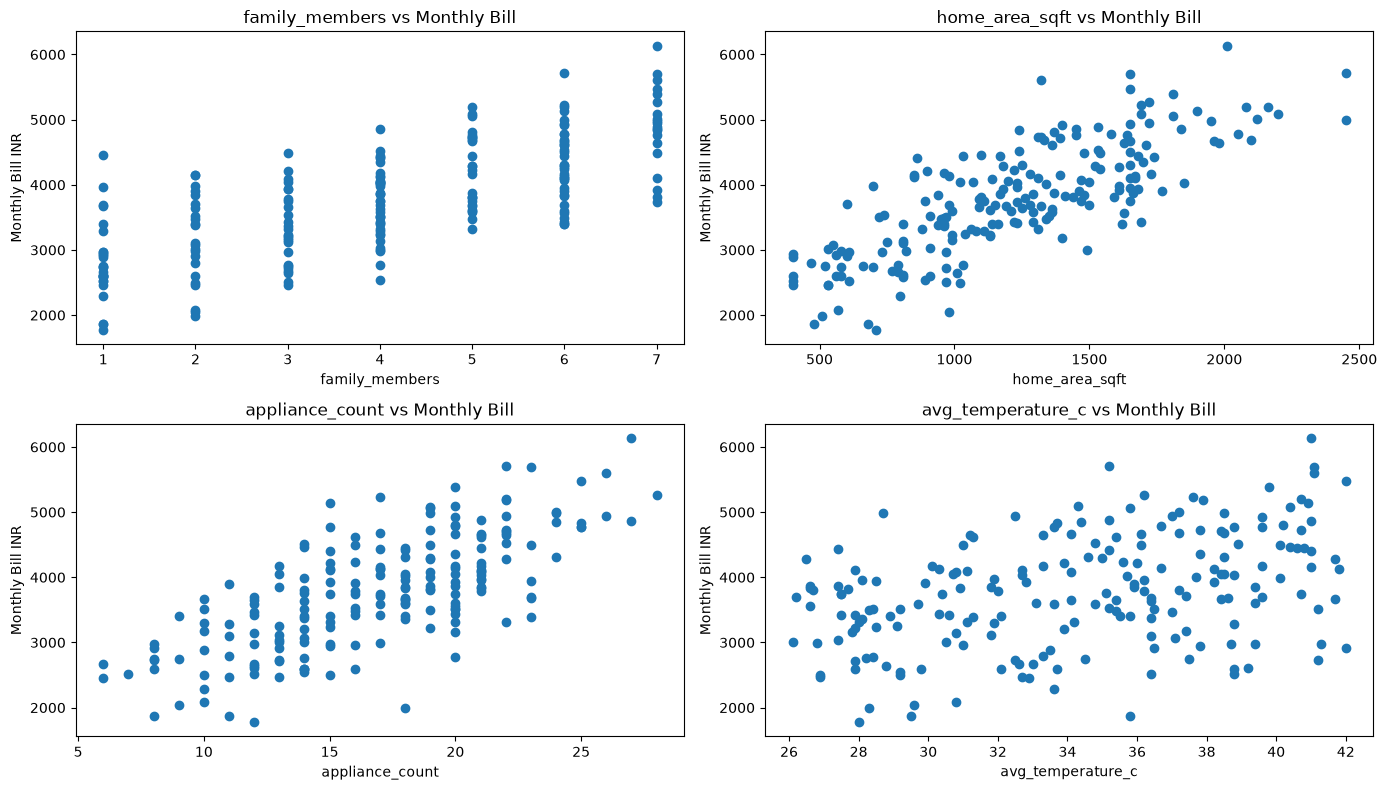

In [17]:
# Creating Space for 5 plot (2 rows 2 cols) - 4 graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].scatter(df[feature], df["monthly_bill_inr"])
    # Adding axes labels    
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Monthly Bill INR")
    axes[i].set_title(f"{feature} vs Monthly Bill")

plt.tight_layout()
plt.show()

In [18]:
# 1st Graph - Positive Correlation
# 2nd Graph - Positive Correlation
# 3rd Graph - Positive Correlation
# 4th Graph - Slight Positive Correlation

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
X_train.shape

(160, 4)

In [21]:
X_test.shape

(40, 4)

In [22]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[141.02, 0.76, 34.48, 75.37]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['family_members','home_area_sqft','appliance_count','avg_temperature_c']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-850.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [23]:
y_pred = multiple_model.predict(X_test)
y_pred

array([4265.32139523, 4401.50665482, 3100.41194571, 3564.14692436,
       5102.20308298, 4170.96302652, 4223.09800564, 2717.64620159,
       3550.12382849, 4947.6036026 , 5676.96337028, 3967.82608598,
       4114.4365354 , 3679.91796652, 2519.01276349, 2713.7230841 ,
       4204.55885851, 5274.57623092, 3665.21605587, 2918.42549858,
       3922.0723867 , 4065.59397189, 4669.83076007, 3105.89499487,
       3000.00451519, 4922.32840144, 3589.88889014, 3055.78342431,
       3070.0060215 , 2959.41827388, 3110.3419855 , 4756.68267107,
       2535.31462846, 4092.94371675, 5258.82762975, 3968.3818258 ,
       3794.4877636 , 2731.19780875, 3220.14267468, 3208.41908067])

In [24]:
y_test.head

<bound method NDFrame.head of 95     4494
15     3689
30     2762
158    3519
128    5192
115    4040
69     4011
170    2731
174    3870
45     4852
66     6137
182    3636
165    3831
78     3429
186    2458
177    2045
56     4054
152    5696
82     3648
68     3400
124    3566
16     4516
148    4309
93     3160
65     2775
60     3925
84     3694
67     2672
125    2544
132    2940
9      2736
18     4498
55     2464
75     4123
150    5714
104    4280
135    3178
137    1867
164    3745
76     2749
Name: monthly_bill_inr, dtype: int64>

In [25]:
results = pd.DataFrame({
    "Actual Bills" : y_test.values,
    "Predicted Bills" : y_pred.round(0).astype(int)
})

results.head(10)

,Actual Bills,Predicted Bills
0,4494,4265
1,3689,4402
2,2762,3100
3,3519,3564
4,5192,5102
5,4040,4171
6,4011,4223
7,2731,2718
8,3870,3550
9,4852,4948


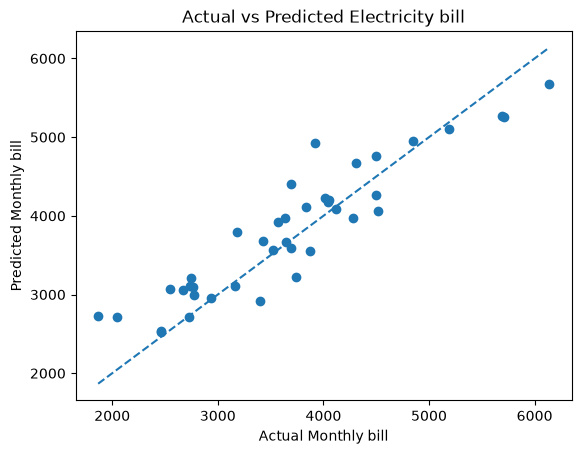

In [26]:
#Visualize the Actual bill vs Predicted bill
plt.scatter(y_test, y_pred)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper],[lower, upper], linestyle="--") 

plt.xlabel("Actual Monthly bill")
plt.ylabel("Predicted Monthly bill")
plt.title("Actual vs Predicted Electricity bill")
plt.show()

In [29]:
#Predicting new house using Multiple Linear Regression
new_house = pd.DataFrame([{
    "family_members": 4,
    "home_area_sqft":1200,
    "appliance_count": 6,
    "avg_temperature_c":35
}])
predicted_bill = multiple_model.predict(new_house[features])[0]
print(round(predicted_bill, 2))

3465.58


In [30]:
#Evaluate the Models Perfomance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE: ",mae)
print("MSE: ", mse)
print("R2 Score: ",r2)

MAE:  318.9093979667897
MSE:  157020.20221318808
R2 Score:  0.8355534231634076
